# Homework 4: Building and applying a classification model 
## Use the 'wine' dataset in the sci-kit learn dataset and the MLPClassifier to build a model and predict the target variable from the feature data

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn import metrics
from sklearn.linear_model import LogisticRegression

## Part 1 
### Model Construction

In [2]:
# Load the data
wine = load_wine()
print(wine.feature_names)
print(wine.target_names)

['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
['class_0' 'class_1' 'class_2']


In [3]:
# feature matrix in an object named X
X = wine.data
# response vector
y = wine.target

print(np.shape(X))
print(np.shape(y))

(178, 13)
(178,)


In [4]:
# Split wine data in train and test data (80:20)
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [5]:
# Feature scaling
# scale the training data
scaler = StandardScaler()
scaler.fit(X_train)

X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [6]:
# now build the neural network using MLPClassifier
mlp = MLPClassifier(hidden_layer_sizes=(10, 10, 10), max_iter=5000)

# now fit the classifer to the training data
mlp.fit(X_train, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(10, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",5000
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",None


## Part 2
### Explore hyperparameter space
You will explore the parameter space of the MLPClassifier model and determine the combination(s) of number of layers and number of neurons that yield the best model accuracy score.

Produce a figure that illustrates the results of your analysis. Write a short paragraph (at least 2 sentences) explaining your results. If more than one combination of layers/neurons results in a high accuracy score (>0.9), which combination of layers/neurons would you use and why?

For each combination of layers/neurons that yields an accuracy score > 0.9, calculate the confusion matrix, precision, recall and f1-score for each target class. Describe the implications of your results for model performance for each target class and choose which layers/neurons you will use in the final version of your model.

In [7]:
scores = {}
scores_list = []
l_range = range(4, 20, 1)

for l in l_range:
    print(l)
    mlp = MLPClassifier(hidden_layer_sizes=(l, l, l), max_iter=5000)
    mlp.fit(X_train, y_train)
    y_pred = mlp.predict(X_test)
    scores[l] = metrics.accuracy_score(y_test, y_pred)
    scores_list.append(metrics.accuracy_score(y_test, y_pred))

4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19


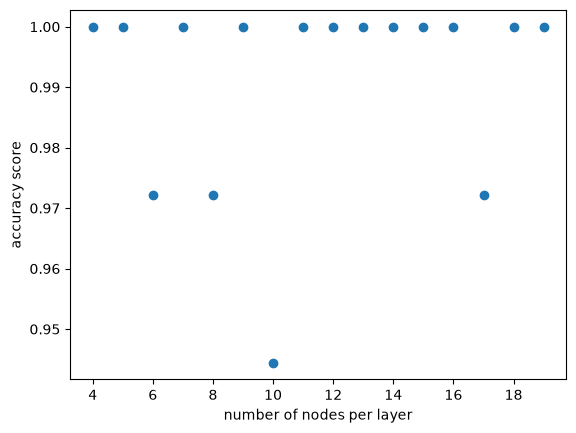

In [8]:
# plot the model accuracy for each value of k
plt.scatter(l_range, scores_list)
plt.xlabel('number of nodes per layer')
plt.ylabel('accuracy score')
plt.show()

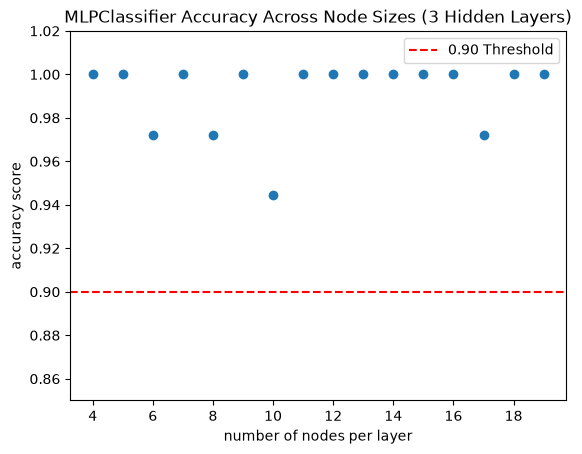

In [9]:
plt.scatter(l_range, scores_list)
plt.axhline(0.90, color='red', linestyle='--', label='0.90 Threshold')
plt.xlabel('number of nodes per layer')
plt.ylabel('accuracy score')
plt.title('MLPClassifier Accuracy Across Node Sizes (3 Hidden Layers)')
plt.ylim(0.85, 1.02)
plt.legend()
plt.show()

This model performed very well across all of the tested configurations with testing accuracies between 0.97 and 1.00. Since none of the tests were below 90% accuracy, both the smaller and larger combinations would be acceptable to use. However, it would be preferable to use smaller hidden layer sizes such as 4,4,4, or 9,9,9, than larger sizes such as 17,17,17. If you choose a smaller size combination, then you will have a lower weight for the computer to go through and you lost the risk of overfitting the data.

In [10]:
# Evaluate confusion matrix, precision, recall, and f1-score for each architecture > 0.90
for l in l_range:
    if scores[l] > 0.90:
        print(f"Architecture: ({l}, {l}, {l}) | Accuracy: {scores[l]:.4f}")
 
        
        # Train model with random_state for consistency
        mlp_eval = MLPClassifier(hidden_layer_sizes=(l, l, l), max_iter=5000, random_state=42)
        mlp_eval.fit(X_train, y_train)
        y_pred = mlp_eval.predict(X_test)
        
        # 1. Confusion Matrix
        print("Confusion Matrix:")
        print(confusion_matrix(y_test, y_pred))
        
        # 2. Precision, Recall, and F1-Score for each target class
        print("\nClassification Report:")
        print(classification_report(y_test, y_pred, target_names=wine.target_names))

Architecture: (4, 4, 4) | Accuracy: 1.0000
Confusion Matrix:
[[14  0  0]
 [ 0 14  0]
 [ 0  0  8]]

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        14
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

Architecture: (5, 5, 5) | Accuracy: 1.0000
Confusion Matrix:
[[13  0  1]
 [ 0 14  0]
 [ 0  0  8]]

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      0.93      0.96        14
     class_1       1.00      1.00      1.00        14
     class_2       0.89      1.00      0.94         8

    accuracy                           0.97        36
   macro avg       0.96      0.98      0.97        36
weighted avg       0.98      0.97      0.97      

### Results of the > 0.90 model selections 
class 0: Is near perfect everytime. Precision (0.93-1.00), recall (0.93-1.00), f1 score (0.96-1.00)
class 1: Is 1.00 across most node configurations (11, 11, 11, and 12, 12, 12 did not have 1.00 for all) 
class 2: 5, 5, 5, and 11, 11, 11, were the only architectures that did not have 1.00 for all of the configurations.
Final choice: The 6,6,6 architecture will be used for the final model because it performed perfectly across all classes and is in the smaller architectutre groups to reduce overfitting. 

## Part 3
### Apply the model with the new tuned values

In [19]:
unknown_wine = pd.read_csv('data/unknown_wine.csv')
print(unknown_wine.columns)

Index(['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
       'total_phenols', 'flavanoids', 'nonflavanoid_phenols',
       'proanthocyanins', 'color_intensity', 'hue',
       'od280/od315_of_diluted_wines', 'proline', 'target'],
      dtype='str')


In [12]:
# unknown_wine['target'] is not in the original column list, need to remove 
unknown_wine_cleaned = unknown_wine.drop(columns=['target']).copy()

In [15]:
# Was having a lot of difficulty to get this to work without error, so I screenshotted this section and put into gemini

#1. Scale the cleaned new wine data
x_new_scaled = scaler.transform(unknown_wine_cleaned.values)

# 2. Fit your model on training data and predict probabilities for the unknown wine
mlp_final = MLPClassifier(hidden_layer_sizes=(6, 6, 6), max_iter=5000, random_state=42)
mlp_final.fit(X_train, y_train)

probs = mlp_final.predict_proba(x_new_scaled)
preds = mlp_final.predict(x_new_scaled)

# 3. Define class names manually (or use target_names from your dataset loader, e.g., dataset.target_names)
target_names = list(wine.target_names)

# 4. Display results for each unknown wine sample
print("Sample probabilities for each unknown wine:")
for i, prob_row in enumerate(probs):
    print(f"\nUnknown wine {i+1} (Predicted: {target_names[preds[i]]}):")
    for j, class_name in enumerate(target_names):
        print(f"  Class {class_name}: {prob_row[j]:.4f}")

Sample probabilities for each unknown wine:

Unknown wine 1 (Predicted: class_0):
  Class class_0: 0.9944
  Class class_1: 0.0001
  Class class_2: 0.0055

Unknown wine 2 (Predicted: class_0):
  Class class_0: 0.9646
  Class class_1: 0.0138
  Class class_2: 0.0215

Unknown wine 3 (Predicted: class_0):
  Class class_0: 0.9913
  Class class_1: 0.0003
  Class class_2: 0.0084

Unknown wine 4 (Predicted: class_0):
  Class class_0: 0.9876
  Class class_1: 0.0001
  Class class_2: 0.0123

Unknown wine 5 (Predicted: class_0):
  Class class_0: 0.9813
  Class class_1: 0.0040
  Class class_2: 0.0147

Unknown wine 6 (Predicted: class_0):
  Class class_0: 0.9742
  Class class_1: 0.0100
  Class class_2: 0.0158

Unknown wine 7 (Predicted: class_0):
  Class class_0: 0.9866
  Class class_1: 0.0042
  Class class_2: 0.0092

Unknown wine 8 (Predicted: class_0):
  Class class_0: 0.9851
  Class class_1: 0.0013
  Class class_2: 0.0136

Unknown wine 9 (Predicted: class_0):
  Class class_0: 0.9904
  Class class_

## Unknown sample results
Function used: predict_proba() 

    -It calculates the probability distribution across the target classes. 
    
Probabilities for each class: 

    -Samples 1-59 were classified as class 0 with strong certainty (> 0.94)
    
    -Samples 60-130 were classified as class 1 with strong certainty (> 0.95)
    
    -Samples 131-178 were classified as class 2 with extremely strong certainty (> 0.99)

All of the samples have have a predicted probability that is greater than 90% for one class. This means that the model is extremely confident about the class of nearly every wine bottle. 